In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from Graphs import Node, Edge, FlowGraph

In [5]:
S1 = Node(name="S1", supply= {"d1" : 300, "d2" : 400}, type="source", capacity=None, fixed_cost=0)
S2 = Node(name="S2", supply= {"d1" : 250, "d2" : 150}, type="source", capacity=None, fixed_cost=0)
S3 = Node(name="S3", supply= {"d1" : 350, "d2" : 250}, type="source", capacity=None, fixed_cost=0)

D1 = Node(name="D1", demand= {"d1" : 150, "d2" : 150}, type="destination", capacity=None, fixed_cost=0)
D2 = Node(name="D2", demand= {"d1" : 200, "d2" : 250}, type="destination", capacity=None, fixed_cost=0)
D3 = Node(name="D3", demand= {"d1" : 175, "d2" : 175}, type="destination", capacity=None, fixed_cost=0)
D4 = Node(name="D4", demand= {"d1" : 225, "d2" : 175}, type="destination", capacity=None, fixed_cost=0)

I1 = Node(name="I1", supply=0, demand=0, type="intermediate", fixed_cost=1000)
I2 = Node(name="I2", supply=0, demand=0, type="intermediate", fixed_cost=800)
I3 = Node(name="I3", supply=0, demand=0, type="intermediate", fixed_cost=1200)
I4 = Node(name="I4", supply=0, demand=0, type="intermediate", fixed_cost=1100)
I5 = Node(name="I5", supply=0, demand=0, type="intermediate", fixed_cost=700)
I6 = Node(name="I6", supply=0, demand=0, type="intermediate", fixed_cost=900)

S1I1 = Edge(origin=S1, destination=I1, variable_cost=2)
S1I2 = Edge(origin=S1, destination=I2, variable_cost=4)
S1I3 = Edge(origin=S1, destination=I3, variable_cost=5)
S1I4 = Edge(origin=S1, destination=I4, variable_cost=7)
S1I5 = Edge(origin=S1, destination=I5, variable_cost=3)
S1I6 = Edge(origin=S1, destination=I6, variable_cost=6)

S2I1 = Edge(origin=S2, destination=I1, variable_cost=3)
S2I2 = Edge(origin=S2, destination=I2, variable_cost=2)
S2I3 = Edge(origin=S2, destination=I3, variable_cost=6)
S2I4 = Edge(origin=S2, destination=I4, variable_cost=8)
S2I5 = Edge(origin=S2, destination=I5, variable_cost=4)
S2I6 = Edge(origin=S2, destination=I6, variable_cost=5)

S3I1 = Edge(origin=S3, destination=I1, variable_cost=1)
S3I2 = Edge(origin=S3, destination=I2, variable_cost=3)
S3I3 = Edge(origin=S3, destination=I3, variable_cost=4)
S3I4 = Edge(origin=S3, destination=I4, variable_cost=6)
S3I5 = Edge(origin=S3, destination=I5, variable_cost=5)
S3I6 = Edge(origin=S3, destination=I6, variable_cost=7)

I1D1 = Edge(origin=I1, destination=D1, variable_cost=5)
I1D2 = Edge(origin=I1, destination=D2, variable_cost=2)
I1D3 = Edge(origin=I1, destination=D3, variable_cost=3)
I1D4 = Edge(origin=I1, destination=D4, variable_cost=4)

I2D1 = Edge(origin=I2, destination=D1, variable_cost=4)
I2D2 = Edge(origin=I2, destination=D2, variable_cost=1)
I2D3 = Edge(origin=I2, destination=D3, variable_cost=5)
I2D4 = Edge(origin=I2, destination=D4, variable_cost=2)

I3D1 = Edge(origin=I3, destination=D1, variable_cost=3)
I3D2 = Edge(origin=I3, destination=D2, variable_cost=4)
I3D3 = Edge(origin=I3, destination=D3, variable_cost=2)
I3D4 = Edge(origin=I3, destination=D4, variable_cost=5)

I4D1 = Edge(origin=I4, destination=D1, variable_cost=5)
I4D2 = Edge(origin=I4, destination=D2, variable_cost=3)
I4D3 = Edge(origin=I4, destination=D3, variable_cost=4)
I4D4 = Edge(origin=I4, destination=D4, variable_cost=1)

I5D1 = Edge(origin=I5, destination=D1, variable_cost=2)
I5D2 = Edge(origin=I5, destination=D2, variable_cost=5)
I5D3 = Edge(origin=I5, destination=D3, variable_cost=3)
I5D4 = Edge(origin=I5, destination=D4, variable_cost=4)

I6D1 = Edge(origin=I6, destination=D1, variable_cost=4)
I6D2 = Edge(origin=I6, destination=D2, variable_cost=2)
I6D3 = Edge(origin=I6, destination=D3, variable_cost=1)
I6D4 = Edge(origin=I6, destination=D4, variable_cost=5)
 
graph = FlowGraph(nodes=[S1, S2, S3, D1, D2, D3, D4, I1, I2, I3, I4, I5, I6],
                  edges=[S1I1, S1I2, S1I3, S1I4, S1I5, S1I6,
                         S2I1, S2I2, S2I3, S2I4, S2I5, S2I6,
                         S3I1, S3I2, S3I3, S3I4, S3I5, S3I6,
                         I1D1, I1D2, I1D3, I1D4,
                         I2D1, I2D2, I2D3, I2D4,
                         I3D1, I3D2, I3D3, I3D4,
                         I4D1, I4D2, I4D3, I4D4,
                         I5D1, I5D2, I5D3, I5D4,
                         I6D1, I6D2, I6D3, I6D4])

In [8]:
status = graph.min_cost_flow()

Model creation time: 0.00 s
Optimal solution found: 8475.00 in 0.14 s


In [9]:
if status == "Optimal":
    products = graph.commodities

    shipments = pd.DataFrame(
        [(u, v, d["variable_cost"], *[abs(d["flow"][k]) for k in products], d["variable_cost"] * sum(d["flow"].values()))
         for u, v, d in graph.edges(data=True) if sum(d["flow"].values()) > 0],
        columns=["from", "to", "cost/unit (euro)", *products, "cost (euro)"],
    )
    display(shipments)

    warehouses = pd.DataFrame(
        [(n, d["open"], d["fixed_cost"], sum(sum(graph.edges[n, v]["flow"].values()) for v in graph.successors(n)))
         for n, d in graph.nodes(data=True) if d["type"] == "intermediate"],
        columns=["warehouse", "open", "fixed cost (euro)", "units handled"],
    )
    display(warehouses)

    sources = pd.DataFrame(
        [(n, k, d["supply"][k], sum(graph.edges[n, v]["flow"][k] for v in graph.successors(n)))
         for n, d in graph.nodes(data=True) if d["type"] == "source" for k in products],
        columns=["source", "product", "supply", "shipped"],
    )
    display(sources)

    transport_cost = shipments["cost (euro)"].sum()
    fixed_cost = (warehouses["open"] * warehouses["fixed cost (euro)"]).sum()
    print(f"Transport cost: {transport_cost:.0f} euro")
    print(f"Fixed cost of open warehouses: {fixed_cost:.0f} euro")
    print(f"Total cost: {graph.result.objective:.0f} euro")

,from,to,cost/unit (euro),d1,d2,cost (euro)
0,S1,I1,2.0,150.0,350.0,1000.0
1,S2,I2,2.0,250.0,150.0,800.0
2,S3,I1,1.0,350.0,225.0,575.0
3,S3,I2,3.0,0.0,25.0,75.0
4,I1,D1,5.0,150.0,150.0,1500.0
5,I1,D2,2.0,175.0,250.0,850.0
6,I1,D3,3.0,175.0,175.0,1050.0
7,I2,D2,1.0,25.0,0.0,25.0
8,I2,D4,2.0,225.0,175.0,800.0


,warehouse,open,fixed cost (euro),units handled
0,I1,1,1000.0,1075.0
1,I2,1,800.0,425.0
2,I3,0,1200.0,0.0
3,I4,0,1100.0,0.0
4,I5,0,700.0,0.0
5,I6,0,900.0,0.0


,source,product,supply,shipped
0,S1,d1,300.0,150.0
1,S1,d2,400.0,350.0
2,S2,d1,250.0,250.0
3,S2,d2,150.0,150.0
4,S3,d1,350.0,350.0
5,S3,d2,250.0,250.0


Transport cost: 6675 euro
Fixed cost of open warehouses: 1800 euro
Total cost: 8475 euro


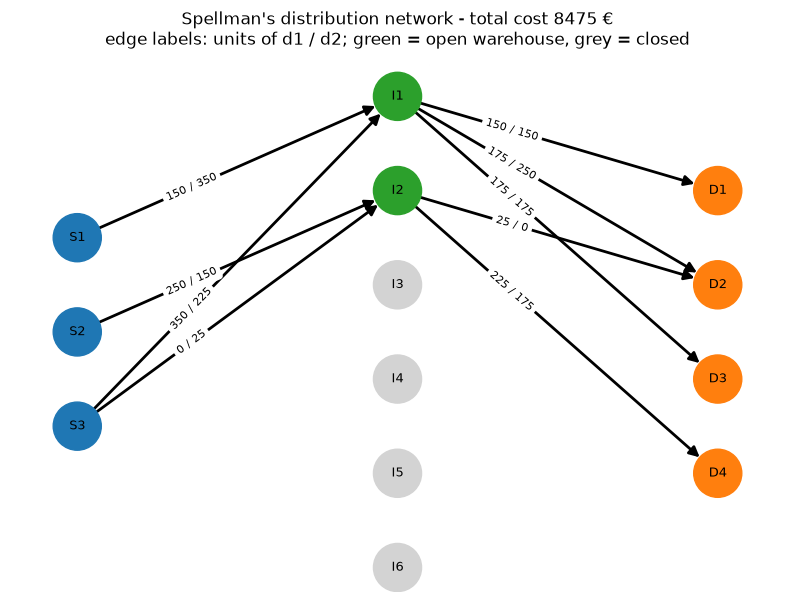

In [10]:
# layout: sources left, intermediate warehouses in the middle, destinations right
layers = {"source": 0, "intermediate": 1, "destination": 2}
pos = {}
for t, x in layers.items():
    names = [n for n, d in graph.nodes(data=True) if d["type"] == t]
    for i, n in enumerate(names):
        pos[n] = (x, -(i - (len(names) - 1) / 2))

colors = []
for n, d in graph.nodes(data=True):
    if d["type"] == "source":
        colors.append("tab:blue")
    elif d["type"] == "destination":
        colors.append("tab:orange")
    else:
        colors.append("tab:green" if d["open"] else "lightgrey")

used = [(u, v) for u, v, d in graph.edges(data=True) if sum(d["flow"].values()) > 0]
labels = {(u, v): " / ".join(f"{abs(d['flow'][k]):.0f}" for k in graph.commodities)
          for u, v, d in graph.edges(data=True) if (u, v) in used}

fig, ax = plt.subplots(figsize=(10, 7))
nx.draw_networkx_nodes(graph, pos, node_color=colors, node_size=1200, ax=ax)
nx.draw_networkx_labels(graph, pos, font_size=9, ax=ax)
nx.draw_networkx_edges(graph, pos, edgelist=used, width=2, arrowsize=15, node_size=1200, ax=ax)
nx.draw_networkx_edge_labels(graph, pos, edge_labels=labels, label_pos=0.35, font_size=8, ax=ax)
ax.set_title(f"Spellman's distribution network - total cost {graph.result.objective:.0f} €\n"
             f"edge labels: units of {' / '.join(graph.commodities)}; green = open warehouse, grey = closed")
ax.axis("off")
plt.show()